# ДЗ 1 — discovery-рекомендации на Yambda-50M

Курс girafe-ai «Рекомендательные системы».

**Задача.** Рекомендовать пользователю десять треков, которых он раньше **не слышал**, и
сравнить на этой задаче пять моделей, написанных с нуля.

**Датасет.** [Yambda-50M](https://huggingface.co/datasets/yandex/yambda) (`yandex/yambda`,
вариант `flat/50m`), Apache 2.0, доступ без токена. Это обезличенные события сервиса
Яндекс Музыка: прослушивания, лайки, дизлайки и их отмены.

**Что считается релевантным.** Новый для пользователя трек, проигранный в тестовом окне
не меньше чем наполовину (`played_ratio_pct >= 50`) — это определение `Listen+` из
карточки датасета. Трек делает «знакомым» любое прослушивание, даже скип: предполагается,
что услышанное уже не открытие.

Исследовательская часть разобрана в девяти блоках: `eda/01-sanity` …
`eda/09-features-leakage`; сводка ограничений — `LIMITATIONS.md`; полные числа
подбора и команды воспроизведения — `models/RESULTS.md`.

## Как воспроизвести

```bash
pip install -r requirements.txt
bash tools/download_data.sh            # сырые данные в data/raw (471 МБ)
python -I tools/build_subsample.py data/raw      # подвыборка
python -I tools/checks/f4_export_embeddings.py data/raw   # аудиовекторы каталога
```

Данные в репозиторий не коммитятся (см. `.gitignore`). Все случайные зёрна
зафиксированы: подвыборка — сид 42, инициализация моделей — сид 42, отрицательные
примеры FM — сид 0.

In [1]:
import os, sys, time, json
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = os.getcwd()
MODELS = os.path.join(ROOT, "models")
sys.path.insert(0, MODELS)
# Данные (523 МБ) в репозиторий не входят, и путь к ним не зашит: common.data_dir()
# смотрит переменную окружения YAMBDA_DATA, затем data/ рядом с кодом. Так один и тот
# же ноутбук работает и там, где данные скачаны внутрь репозитория, и там, где рядом.
from common import data_dir
DATA = data_dir()
SUB = os.path.join(DATA, "subsample")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("модели:", os.path.relpath(MODELS, ROOT))
print("подвыборка:", os.path.relpath(SUB, ROOT))

# Гиперпараметры, выбранные на val сетками из models/ (раздел 5 печатает сетки целиком).
# Здесь они собраны в одном месте, чтобы финальные прогоны на test не разъехались.
KNN_Q, KNN_K = 0.7, 200
IALS_F, IALS_REG, IALS_A = 128, 0.05, 1.0
EASE_LAM = 500.0

модели: models
подвыборка: ..\hw1\data\subsample


## 1. Загрузка и описание данных

**Источник.** `yandex/yambda`, вариант `flat/50m`. Качается скриптом
`tools/download_data.sh` (451 МБ событий плюс 21 МБ списка треков с эмбеддингами).

**Поля, которые используются.**

| поле | смысл |
|---|---|
| `uid` | обезличенный пользователь |
| `item_id` | трек |
| `timestamp` | время события, **единица — одна секунда** (см. ниже) |
| `played_ratio_pct` | какую долю трека проиграли, в процентах |
| `is_organic` | нашёл пользователь трек сам (1) или по рекомендации сервиса (0) |
| `track_length_seconds` | длительность трека |
| `artist_id`, `album_id` | метаданные из отдельных таблиц соответствий |
| `normalized_embed` | аудиовектор трека, 128 чисел, норма 1 |

**Про единицу времени.** Карточка датасета говорит о 5-секундной гранулярности, и это
легко прочитать как «единица равна пяти секундам». Единица — одна секунда, кратность пяти
относится к округлению. Блок 02 поймал ошибку тремя независимыми проверками: суточный
ритм виден только при периоде 86 400, интервал между соседними прослушиваниями равен
проигранным секундам (медиана отношения 1,02), и все значения кратны 5. Горизонт данных —
301 сутки, ровно 43 недели.

**Что считается взаимодействием.** Это важно для коридора задания (100 тыс. … 2 млн).
Взаимодействием мы считаем **уникальную пару (пользователь, трек)** — именно пары
получают на вход все пять моделей, матрица строится по ним. Повторные прослушивания одной
пары не отдельные взаимодействия, а сигнал внутри одной: из них собираются число
повторов и качество первого прослушивания (это материал таргета модели 5). Строк событий
в подвыборке примерно вчетверо больше, чем пар, и ниже печатаются оба числа.

In [2]:
# исходный объём — по сырым файлам, без их загрузки в память
RAW = os.path.join(DATA, "raw")
listens = pl.scan_parquet(os.path.join(RAW, "listens.parquet"))
print("таблица прослушиваний: %d событий, %d пользователей, %d треков" % (
    listens.select(pl.len()).collect().item(),
    listens.select(pl.col("uid").n_unique()).collect().item(),
    listens.select(pl.col("item_id").n_unique()).collect().item()))
likes = pl.scan_parquet(os.path.join(RAW, "likes.parquet"))
print("таблица лайков:        %d событий, %d пользователей, %d треков" % (
    likes.select(pl.len()).collect().item(),
    likes.select(pl.col("uid").n_unique()).collect().item(),
    likes.select(pl.col("item_id").n_unique()).collect().item()))
print("\nкарточка датасета заявляет 10 000 пользователей и 934 057 треков — это по всем")
print("типам событий вместе; в прослушиваниях их меньше, часть пользователей и треков")
print("встречается только в лайках и дизлайках.")

таблица прослушиваний: 46467212 событий, 9238 пользователей, 877168 треков
таблица лайков:        881456 событий, 8283 пользователей, 181304 треков

карточка датасета заявляет 10 000 пользователей и 934 057 треков — это по всем
типам событий вместе; в прослушиваниях их меньше, часть пользователей и треков
встречается только в лайках и дизлайках.


In [3]:
train = pl.read_parquet(os.path.join(SUB, "train.parquet"))
val = pl.read_parquet(os.path.join(SUB, "val.parquet"))
test = pl.read_parquet(os.path.join(SUB, "test.parquet"))
catalog = pl.read_parquet(os.path.join(SUB, "catalog.parquet"))
users = pl.read_parquet(os.path.join(SUB, "users.parquet"))

events = train.height + val.height + test.height
# уникальные пары считаются по всем окнам СРАЗУ: пара, встречающаяся и в train, и в test,
# остаётся одним взаимодействием. Сумма по окнам дала бы 2 451 098 — это двойной счёт.
pairs = (pl.concat([train.select("uid", "item_id"), val.select("uid", "item_id"),
                    test.select("uid", "item_id")]).unique().height)
fit_nnz = pl.concat([train.select("uid", "item_id"),
                     val.select("uid", "item_id")]).unique().height
print("итоговая подвыборка")
print("  пользователей %d, треков %d, артистов %d" % (
    users.height, catalog.height, catalog["artist_id"].n_unique()))
print("  взаимодействий (уникальных пар) %d  <- коридор задания 100 000 … 2 000 000" % pairs)
print("  из них в обучающем окне train+val %d, впервые в тесте %d" % (fit_nnz, pairs - fit_nnz))
print("  строк событий %d — это повторные прослушивания тех же пар" % events)
print("  по окнам: train %d / val %d / test %d строк" % (train.height, val.height, test.height))

итоговая подвыборка
  пользователей 3000, треков 10000, артистов 3816
  взаимодействий (уникальных пар) 1966410  <- коридор задания 100 000 … 2 000 000
  из них в обучающем окне train+val 1828689, впервые в тесте 137721
  строк событий 7969893 — это повторные прослушивания тех же пар
  по окнам: train 6534804 / val 747400 / test 687689 строк


## 2. EDA и подготовка

Полный разбор — в блоках `eda/`. Здесь воспроизведены те проверки, на которых стоят
решения об очистке и отборе.

**Пропуски и дубликаты (блок 01).** Пропусков в ключевых полях нет. Полностью совпадающих
строк 225 625 (0,49 %) — это артефакт логирования, а не настоящие повторы: у 1 711 ключей
при совпадении времени расходится `is_organic`. Дубликаты не схлопываются, потому что
модели всё равно работают с парами, а не со строками. `played_ratio_pct > 100` бывает
(трек «проигран» больше своей длины) и обрезается по 100 при расчёте качества
знакомства; `track_length_seconds = 0` встречается, такие строки в таргет не идут.

**Фильтр пользователей (блок 03).** Из 10 000 убраны: 762 без прослушиваний, 125
холодных, 36 «перелистывающих» (почти все события — скипы), и оставлены те, у кого не
меньше 5 прослушиваний в сутки 0…279. Остался пул 9 055, из него случайно (сид 42)
отобраны 3 000.

**Каталог (блок 04).** Топ-10 000 треков по числу слушателей пула, отобранный **только по
истории до теста**. Хвост Yambda чудовищный: половину треков знает один человек, и без
ограничения каталога матрица не влезает ни в бюджет задания, ни в память под EASE. Цена
известна и идёт в ограничения: достижимыми остаются 34,8 % релевантных новинок.

In [4]:
fit = pl.concat([train, val])                      # обучающее окно финальной модели
fit_pairs = fit.select("uid", "item_id").unique()
per_user = fit_pairs.group_by("uid").len().rename({"len": "n_items"})
per_item = fit_pairs.group_by("item_id").len().rename({"len": "n_users"})
density = fit_pairs.height / (users.height * catalog.height)

print("треков на пользователя: медиана %.0f, q10 %.0f, q90 %.0f, максимум %d" % (
    per_user["n_items"].median(), per_user["n_items"].quantile(0.1),
    per_user["n_items"].quantile(0.9), per_user["n_items"].max()))
print("слушателей на трек: медиана %.0f, минимум %d, максимум %d" % (
    per_item["n_users"].median(), per_item["n_users"].min(), per_item["n_users"].max()))
print("плотность матрицы обучения %.2f %% (разреженность %.2f %%)" % (
    100 * density, 100 * (1 - density)))
print("метаданные внутри каталога: артист у %.1f %%, аудиовектор у %.2f %%" % (
    100 * catalog["artist_id"].is_not_null().mean(), 100 * catalog["has_embed"].mean()))

треков на пользователя: медиана 489, q10 59, q90 1308, максимум 3679
слушателей на трек: медиана 129, минимум 58, максимум 1738
плотность матрицы обучения 6.10 % (разреженность 93.90 %)
метаданные внутри каталога: артист у 100.0 %, аудиовектор у 96.75 %


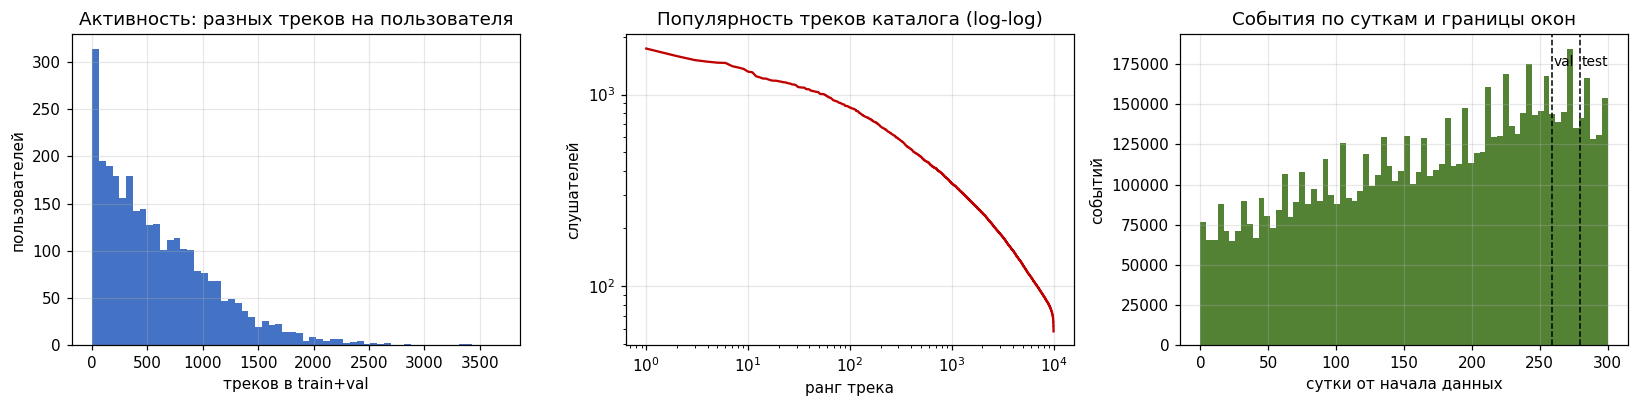

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

ax[0].hist(per_user["n_items"].to_numpy(), bins=60, color="#4472c4")
ax[0].set_title("Активность: разных треков на пользователя")
ax[0].set_xlabel("треков в train+val"); ax[0].set_ylabel("пользователей")

y = np.sort(per_item["n_users"].to_numpy())[::-1]
ax[1].plot(np.arange(1, len(y) + 1), y, color="#c00000")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Популярность треков каталога (log-log)")
ax[1].set_xlabel("ранг трека"); ax[1].set_ylabel("слушателей")

days = pl.concat([train, val, test])["timestamp"].to_numpy() // 86400
ax[2].hist(days, bins=70, color="#548235")
for b, name in ((259, "val"), (280, "test")):
    ax[2].axvline(b, color="k", ls="--", lw=1)
    ax[2].text(b + 1, ax[2].get_ylim()[1] * 0.9, name, fontsize=9)
ax[2].set_title("События по суткам и границы окон")
ax[2].set_xlabel("сутки от начала данных"); ax[2].set_ylabel("событий")

fig.tight_layout(); plt.show()

Левый график — почему нужен фильтр по активности: без него треть пользователей имела бы
профиль из нескольких треков, и метрика мерила бы их активность, а не качество модели.
Средний — тот самый хвост: популярность падает по прямой в log-log, то есть без
ограничения каталога почти все кандидаты были бы треками, которых никто не знает.
Правый — ровный поток событий без провалов логирования и недельная рябь (±10 %), из-за
которой окна сделаны кратными неделе.

## 3. Протокол оценки

Единый для всех пяти моделей, зашит в `models/common.py` — чтобы сравнение было честным,
ни одна модель не может поменять ни кандидатов, ни критерий релевантности.

**Разбиение — временное** (timestamp есть, значит случайное деление запрещено себе самому:
оно подсматривало бы будущее). Горизонт 301 сутки = 43 недели делится на три отрезка,
кратных неделе, чтобы недельная сезонность не сдвигала окна относительно друг друга:

| окно | сутки | роль |
|---|---|---|
| train | 0…258 (37 недель) | обучение при подборе гиперпараметров |
| val | 259…279 (3 недели) | подбор гиперпараметров |
| test | 280…300 (3 недели) | финальное сравнение |

Финальные модели учатся на train + val и мерятся на test. Признаки, популярность и
таргеты пересчитываются на каждой стадии заново по своему окну — иначе подбор видел бы
статистику теста.

**Кандидаты.** Каталог 10 000 треков **минус всё, что пользователь слушал в обучающем
окне**. Это и есть постановка discovery: знакомый трек не может попасть в выдачу по
построению, а не штрафом.

**Новые пользователи и объекты.** Новых треков внутри каталога нет по построению — он
отобран по истории до теста, у каждого трека есть сигнал. Пользователи, у которых после
ограничения каталогом профиль в обучающем окне пустой, получают нейтральные значения
признаков плюс флаг `user_has_profile`, но из метрики исключаются: рекомендовать им
нечего, кроме популярного, и их числа мерили бы бейзлайн внутри каждой модели (решение блока 09). Из 3 000 пользователей профиль есть у 2 985, а оцениваются те, у кого
есть ещё и релевантная новинка в тесте.

**Метрика, зафиксированная до подбора — NDCG@10.** Нормировка на
`idealDCG@min(10, число релевантных)`: иначе пользователь с двумя релевантными треками
имел бы заведомо недостижимый максимум, и метрика складывалась бы из того, кто сколько
слушает. Вторая метрика — **Recall@10**: она отвечает на прямой вопрос «какую долю
открытий мы угадали», тогда как NDCG отвечает за порядок внутри десятки. Третьей печатаем
HitRate@10 — доля пользователей, у которых в десятке есть хотя бы одно попадание.

In [6]:
from common import load, evaluate, report, K
d_val = load("val")
d_test = load("test")
print(d_val)
print(d_test)
print("\nK =", K)

Data(stage=val, пользователей 3000, треков 10000, оцениваемых 2361, релевантных пар 101154, профиль есть у 2860)
Data(stage=test, пользователей 3000, треков 10000, оцениваемых 2607, релевантных пар 88199, профиль есть у 2985)

K = 10


## 4. Пять моделей

Все пять реализованы с нуля на numpy/scipy: библиотек рекомендательных моделей в
зависимостях нет. Каждая живёт в своём файле в `models/`, ниже — постановка, формула и
пространство поиска.

Гиперпараметры подбирались **сетками на val** скриптами из `models/` (команды — в
`models/RESULTS.md`), здесь обучаются финальные конфигурации на train + val и мерятся на
test. Полные сетки приведены таблицами в разделе 5.

### Модель 1 — item-based kNN (`models/run_knn.py`)

Близость треков считается по бинарной матрице «слушал / не слушал», с показателем
подавления популярности $q$:

$$s_{ij} = \frac{|U_i \cap U_j|}{(n_i)^q (n_j)^q},\qquad s_{ii} = 0,$$

где $n_i$ — число слушателей трека. При $q = 0{,}5$ это косинус. У каждого трека
остаются только $k$ ближайших соседей, остальные близости обнуляются. Оценка кандидата —
сумма близостей от знакомых треков пользователя: $\hat r_{uj} = \sum_{i \in I_u} s_{ij}$.

Пространство поиска: $q \in \{0{,}3;\ 0{,}5;\ 0{,}7;\ 0{,}9\}$, $k \in \{50, 100, 200, 500\}$.

In [7]:
from run_knn import fit_knn
t0 = time.time()
scores_knn = fit_knn(d_test, q=KNN_Q, k=KNN_K)
res = {}
res["kNN"] = evaluate(d_test, scores_knn)
report("kNN q=%g k=%d" % (KNN_Q, KNN_K), res["kNN"])
print("обучение и предсказание: %.0f с" % (time.time() - t0))

kNN q=0.7 k=200        test  пользователей 2607  NDCG@10 0.06731  Recall@10 0.02698  HitRate@10 0.3245
обучение и предсказание: 11 с


### Модель 2 — iALS (`models/run_ials.py`)

ALS для неявного отклика (Hu, Koren, Volinsky, 2008). Наблюдения бинаризуются
($p_{ui} = 1$, если пара встречалась), а сила наблюдения уходит в вес — уверенность
$c_{ui} = \alpha r_{ui}$, где $r_{ui}$ — число прослушиваний пары. Минимизируется

$$\sum_{u,i} w_{ui}\,(p_{ui} - x_u^\top y_i)^2
  + \lambda\Big(\sum_u \|x_u\|^2 + \sum_i \|y_i\|^2\Big),$$

где $w_{ui} = c_{ui}$ на наблюдённых парах и $w_{ui} = 1$ на всех остальных. Сумма идёт по
всем парам: ненаблюдённые тянут вектора к нулю с единичным весом и дают первый член
формулы ниже, общий для всех пользователей. Отсюда видно, почему на val выигрывает
$\alpha = 1$: при нём пара, прослушанная один раз, весит столько же, сколько
ненаблюдённая, и отличается от неё только целью $p$, а большие $\alpha$ раздувают вес
повторов у популярного. При фиксированных $Y$ каждый пользователь решается отдельно:

$$x_u = \big(Y^\top Y + Y_u^\top (C_u - I) Y_u + \lambda I\big)^{-1} Y_u^\top c_u.$$

Первый член общий для всех пользователей и считается один раз за полушаг — поэтому цена
шага линейна по числу наблюдений. Система решается точно, `np.linalg.solve`.

Пространство поиска: $\lambda \in \{0{,}01;\ 0{,}05;\ 0{,}2\}$,
$\alpha \in \{1, 10, 40\}$ при factors = 64, затем проверка factors = 128 при лучших
$(\lambda, \alpha)$.

In [8]:
from run_ials import fit_ials
t0 = time.time()
scores_ials = fit_ials(d_test, factors=IALS_F, reg=IALS_REG, alpha=IALS_A)
res["iALS"] = evaluate(d_test, scores_ials)
report("iALS f=%d reg=%g a=%g" % (IALS_F, IALS_REG, IALS_A), res["iALS"])
print("обучение: %.0f с" % (time.time() - t0))

iALS f=128 reg=0.05 a=1 test  пользователей 2607  NDCG@10 0.07278  Recall@10 0.02936  HitRate@10 0.3675
обучение: 147 с


### Модель 3 — EASE (`models/run_ease.py`)

Линейная модель «трек-трек» с замкнутым решением: ищется матрица $B$ с нулевой
диагональю, восстанавливающая профиль из самого себя, $\hat R = X B$. Решение

$$G = X^\top X + \lambda I,\qquad P = G^{-1},\qquad
  B = -\frac{P}{\operatorname{diag}(P)},\qquad B_{ii} = 0.$$

Обнуление диагонали и есть вся суть: без него модель скопировала бы профиль. Каталог в
10 000 треков выбран в блоке 04 именно под эту модель — обращение матрицы
10 000 x 10 000 занимает 30 с с пиком 3 ГБ, а на 15 000 уже не влезает в память.

Пространство поиска: $\lambda \in \{50, 100, 250, 500, 1000, 2500\}$.

In [9]:
from run_ease import ease, binary
t0 = time.time()
X = binary(d_test)
B = ease(X, EASE_LAM)
scores_ease = (X @ B).astype(np.float32)
del B
res["EASE"] = evaluate(d_test, scores_ease)
report("EASE lambda=%g" % EASE_LAM, res["EASE"])
print("обучение: %.0f с" % (time.time() - t0))

EASE lambda=500        test  пользователей 2607  NDCG@10 0.07836  Recall@10 0.03032  HitRate@10 0.3828
обучение: 27 с


### Модель 4 — FM с метапризнаками (`models/run_fm.py`)

Гибридная факторизационная машина: трек представлен не только своим id, но и
содержательными признаками, то есть одним id дело не ограничивается, как и требует
задание.

$$q_i = V_i + E_i W + A_{\text{artist}(i)},\qquad
  \hat r_{ui} = \langle P_u, q_i \rangle + b_i,$$

где $V_i$ — вектор самого трека, $E_i$ — аудиоэмбеддинг (128 чисел, нормированный:
блок 09 намерил, что нормы `embed` различаются в восемь раз), $W$ — обучаемая проекция
аудио в скрытое пространство, $A$ — вектор артиста. Обучение — BPR на мини-батчах: на
каждую положительную пару берётся случайный отрицательный кандидат из незнакомых,

$$\mathcal{L} = -\log \sigma(\hat r_{ui} - \hat r_{uj}).$$

**Почему эти признаки.** Аудиовектор и артист — всё, что известно о треке **в момент
рекомендации** и не зависит от будущего поведения; машинный аудит утечек в блоке 09
проверял именно это. Альбом проверен тремя правилами и отброшен с измерением: для 68,3 %
каталога он дублирует `item_id` (в альбоме один трек каталога), то есть был бы вторым
именем трека, а не признаком. У 325 треков каталога аудиовектора нет — им нули.

Модель написана на numpy целиком, без готовых реализаций FM.
Число эпох не подбиралось — равный бюджет в 20 эпох у всех вариантов.

In [10]:
# FM обучается дольше остальных (BPR, 20 эпох), поэтому берём готовые оценки, если
# fm_one.py уже их посчитал, и обучаем заново только если файла нет.
from run_fm import FM
p_fm = os.path.join(MODELS, "scores_fm.npy")
t0 = time.time()
if os.path.exists(p_fm):
    scores_fm = np.load(p_fm)
    print("оценки FM загружены из scores_fm.npy (обучено fm_one.py: 20 эпох, dim=64)")
else:
    scores_fm = FM(d_test, dim=64, lr=0.05, reg=0.01).fit(epochs=20).scores()
    np.save(p_fm, scores_fm)
    print("FM обучена здесь: %.0f с" % (time.time() - t0))
res["FM с аудио"] = evaluate(d_test, scores_fm)
report("FM (аудио + артист)", res["FM с аудио"])

   аудиовекторов 9675/10000, артистов 3816


FM обучена здесь: 809 с


FM (аудио + артист)    test  пользователей 2607  NDCG@10 0.07250  Recall@10 0.02816  HitRate@10 0.3794


### Модель 5 — iALS со своим целевым сигналом (`models/run_model5.py`, `models/target.py`)

Алгоритм тот же, что в модели 2, меняется **только то, что считается положительным
сигналом**. Это не подкрутка гиперпараметров и не замена весов confidence: таргет
собирается из трёх измеренных в блоке 05 вещей.

$$r(u,i) = \min(n, C)\cdot q(r_0) + \beta \cdot L,\qquad C = 20,\ \beta = 15.$$

* $\min(n, C)$ — повторы с насыщением. Рост линейный, а не логарифмический: P(лайк)
  растёт по повторам почти линейно (+1,6…1,8 п. п. на повтор) до $n \approx 20$, и лишь
  затем прирост падает до +1,21, +0,67, +0,12 и уходит в минус.
* $q(r_0)$ — качество знакомства по **первому** прослушиванию, немонотонное: скип
  (0–1 %) → 0,35, 2–49 % → 0,75, 50–98 % → 1,00, 99–100 % → **0,60**. Зона «доиграл до
  самого конца» хуже зоны 50–98 % на всех уровнях повторов — признак фонового
  воспроизведения, когда треком никто не управлял. Скип получает не ноль, а 0,35: пара
  с первым скипом при $n \ge 11$ всё равно даёт P(лайк) 21,4 %.
* $L$ — лайк «при знакомстве»: поставленный не раньше **начала** первого воспроизведения
  пары и не снятый в течение часа. Граница именно такая, потому что прослушивание
  помечается концом воспроизведения, и 31,4 % лайков формально «раньше» своего
  прослушивания — артефакт записи, а не внешний канал (решение блока 09).
* `is_organic` в таргет не входит: он маркирует канал знакомства, а не силу предпочтения.

Коэффициент $\beta = 15$ выбран из трёх вариантов: это тот уровень повторов,
на котором P(лайк) достигает 40 %, а верхние 2,5 % пар держат 22,5 % массы таргета —
ниже порога 26,1 %, которым блок 05 предупреждал о перекосе.

**Сравнение с базовым iALS идёт по единому протоколу:** те же factors, reg, alpha, те же
кандидаты и та же метрика; отличается только матрица, на которой модель учится.

In [11]:
from target import VARIANTS, build
cfg = VARIANTS["B"]
ui, ii, w, stats = build(d_test, cap=cfg["cap"], like_bonus=cfg["like_bonus"])
print("таргет: пар %d, лайков при знакомстве %d, масса от лайков %.1f %%, "
      "верхние 2,5 %% пар держат %.1f %%" % (
          stats["pairs"], stats["likes"], 100 * stats["mass_from_likes"],
          100 * stats["mass_top"]))
t0 = time.time()
scores_m5 = fit_ials(d_test, weights_coo=(ui, ii, w), factors=IALS_F, reg=IALS_REG, alpha=IALS_A)
res["Модель 5"] = evaluate(d_test, scores_m5)
report("Модель 5 (C=20, beta=15)", res["Модель 5"])
print("обучение: %.0f с" % (time.time() - t0))

таргет: пар 1835987, лайков при знакомстве 93717, масса от лайков 25.8 %, верхние 2,5 % пар держат 22.5 %


Модель 5 (C=20, beta=15) test  пользователей 2607  NDCG@10 0.07501  Recall@10 0.02994  HitRate@10 0.3728
обучение: 146 с


### Контроль — Popularity и случайная выдача

Не из списка задания, но без них не видно, сколько даёт персонализация.

In [12]:
pop = d_test.known.sum(0).astype(np.float32)        # разных слушателей на трек
res["Popularity"] = evaluate(d_test, np.broadcast_to(pop, (d_test.n_users, d_test.n_items)))
report("Popularity", res["Popularity"])
rng = np.random.default_rng(42)
res["Random"] = evaluate(d_test, rng.random((d_test.n_users, d_test.n_items), dtype=np.float32))
report("Random", res["Random"])

Popularity             test  пользователей 2607  NDCG@10 0.03988  Recall@10 0.01341  HitRate@10 0.1922


Random                 test  пользователей 2607  NDCG@10 0.00390  Recall@10 0.00099  HitRate@10 0.0353


## 5. Сравнение на тесте

Обе метрики при K = 10, на одних и тех же 2 607 пользователях, одних кандидатах и одном
критерии релевантности.

In [13]:
ORDER = ["Random", "Popularity", "kNN", "FM с аудио", "iALS", "Модель 5", "EASE"]
TUNED = {"Random": "—", "Popularity": "—",
         "kNN": "q = %g, k = %d" % (KNN_Q, KNN_K),
         "FM с аудио": "dim = 64, lr = 0,05, 20 эпох",
         "iALS": "f = %d, reg = %g, alpha = %g" % (IALS_F, IALS_REG, IALS_A),
         "Модель 5": "C = 20, beta = 15",
         "EASE": "lambda = %g" % EASE_LAM}
rows = [(n, res[n]["NDCG@10"], res[n]["Recall@10"], res[n]["HitRate@10"], TUNED[n])
        for n in ORDER if n in res]
print("%-14s %10s %11s %11s   %s" % ("модель", "NDCG@10", "Recall@10", "HitRate@10", "подбор"))
for n, a, b, c, t in rows:
    print("%-14s %10.5f %11.5f %10.1f %%   %s" % (n, a, b, 100 * c, t))

модель            NDCG@10   Recall@10  HitRate@10   подбор
Random            0.00390     0.00099        3.5 %   —
Popularity        0.03988     0.01341       19.2 %   —
kNN               0.06731     0.02698       32.5 %   q = 0.7, k = 200
FM с аудио        0.07250     0.02816       37.9 %   dim = 64, lr = 0,05, 20 эпох
iALS              0.07278     0.02936       36.7 %   f = 128, reg = 0.05, alpha = 1
Модель 5          0.07501     0.02994       37.3 %   C = 20, beta = 15
EASE              0.07836     0.03032       38.3 %   lambda = 500


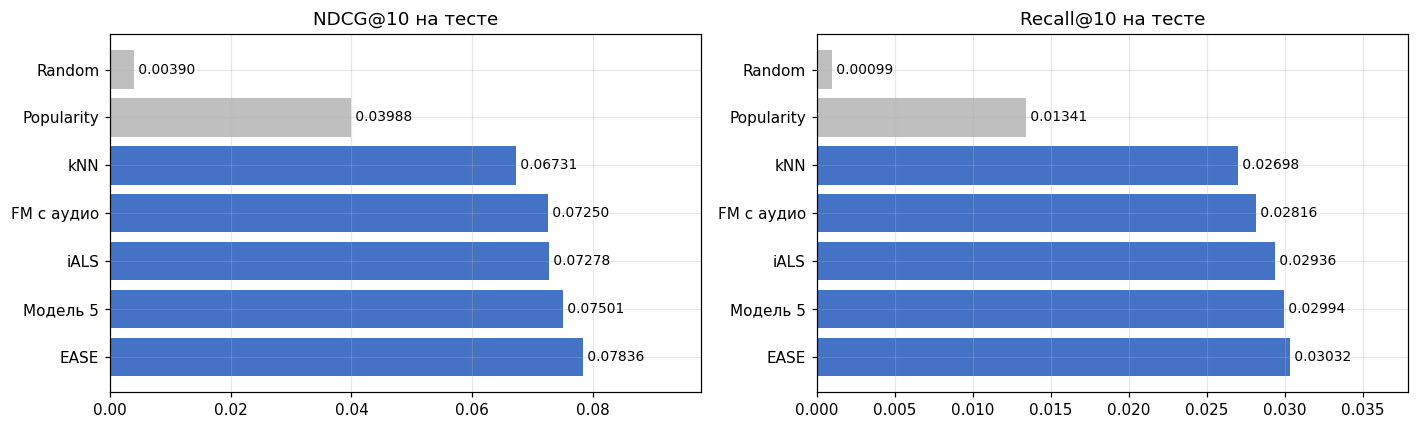

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = [r[0] for r in rows]
for i, (metric, idx) in enumerate((("NDCG@10", 1), ("Recall@10", 2))):
    vals = [r[idx] for r in rows]
    bars = ax[i].barh(names, vals, color=["#bfbfbf", "#bfbfbf"] + ["#4472c4"] * (len(names) - 2))
    ax[i].set_title(metric + " на тесте"); ax[i].invert_yaxis()
    for b, v in zip(bars, vals):
        ax[i].text(v, b.get_y() + b.get_height() / 2, " %.5f" % v, va="center", fontsize=9)
    ax[i].set_xlim(0, max(vals) * 1.25)
fig.tight_layout(); plt.show()

### Пространства поиска целиком

Сетки прогоняются скриптами из `models/` (`python -I models/run_ease.py` и так далее),
здесь приведены их результаты. Полные таблицы — в `models/RESULTS.md`.

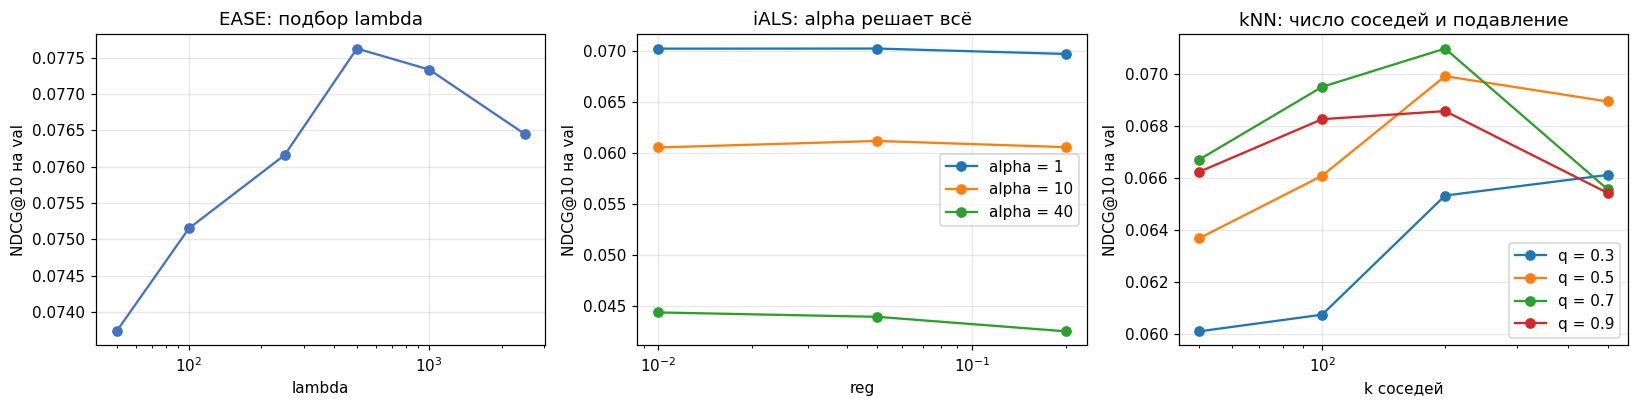

In [15]:
GRIDS = json.load(open(os.path.join(MODELS, "grids.json"), encoding="utf-8"))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

g = GRIDS["ease"]
ax[0].plot(g["lambda"], g["ndcg"], "o-", color="#4472c4")
ax[0].set_xscale("log"); ax[0].set_title("EASE: подбор lambda")
ax[0].set_xlabel("lambda"); ax[0].set_ylabel("NDCG@10 на val")

for a_val, curve in GRIDS["ials_alpha"].items():
    ax[1].plot(curve["reg"], curve["ndcg"], "o-", label="alpha = " + a_val)
ax[1].set_xscale("log"); ax[1].legend(); ax[1].set_title("iALS: alpha решает всё")
ax[1].set_xlabel("reg"); ax[1].set_ylabel("NDCG@10 на val")

for q_val, curve in GRIDS["knn"].items():
    ax[2].plot(curve["k"], curve["ndcg"], "o-", label="q = " + q_val)
ax[2].set_xscale("log"); ax[2].legend(); ax[2].set_title("kNN: число соседей и подавление")
ax[2].set_xlabel("k соседей"); ax[2].set_ylabel("NDCG@10 на val")

fig.tight_layout(); plt.show()

## 6. Новизна: анализ по артистам и реранжирование

Discovery имеет ступени: знакомый трек (в выдаче невозможен по построению), новый трек
знакомого артиста и совсем новый артист. Вторую ступень разбираем отдельно, потому что
«не слышал этот трек» и «не слышал этого исполнителя» — очень разные открытия.

Правило реранжирования одинаково для всех моделей:

$$s' = s - \lambda\,[\text{трек знаком}] - \mu\,[\text{артист знаком}].$$

Первое слагаемое на кандидатах тождественно нулевое (знакомые треки уже исключены),
поэтому строится сетка по $\mu$. Оценки предварительно стандартизуются внутри
пользователя, иначе $\mu$ значила бы для разных моделей разное.

Числа считает `models/run_analysis.py`; ниже — его результат.

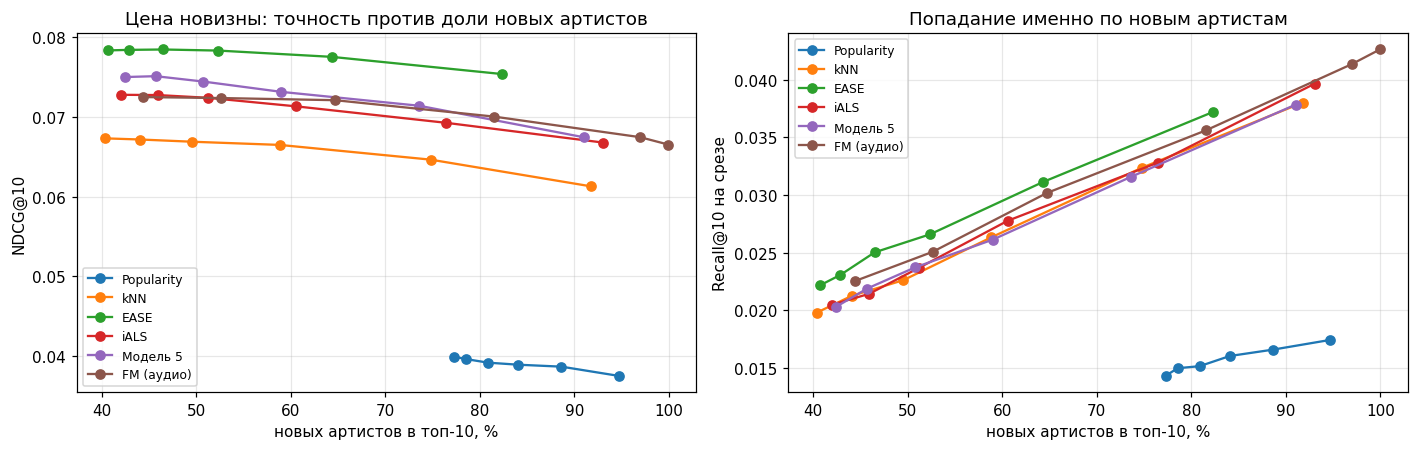

In [16]:
CURVES = np.load(os.path.join(MODELS, "curves.npy"), allow_pickle=True).item()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, pts in CURVES.items():
    share = [100 * p["new_artist_share"] for p in pts]
    ax[0].plot(share, [p["ndcg"] for p in pts], "o-", label=name)
    ax[1].plot(share, [p["recall_new_artist"] for p in pts], "o-", label=name)
ax[0].set_title("Цена новизны: точность против доли новых артистов")
ax[0].set_xlabel("новых артистов в топ-10, %"); ax[0].set_ylabel("NDCG@10")
ax[1].set_title("Попадание именно по новым артистам")
ax[1].set_xlabel("новых артистов в топ-10, %"); ax[1].set_ylabel("Recall@10 на срезе")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 7. Выводы

**1. Задача решаема, но абсолютные значения метрик низкие по построению.** Все пять моделей
почти вдвое обходят Popularity, а тот в десять раз лучше случайной выдачи. При этом внутри
подвыборки на новые треки приходится лишь 33,0 % релевантных событий, а каталог топ-10 000
оставляет достижимыми 34,8 % релевантных новинок — сравнивать эти числа можно только между
моделями этой работы.

**2. Лучшая модель — EASE, но размер её преимущества обсуждать нельзя.** 0,07836 по NDCG@10 и
первое место по обеим метрикам. Однако отрыв от модели 5 (0,0017 от её лучшего прогона) равен
порядку разброса модели 5 между случайными зёрнами. Любопытно, что сильнее всего разошлись две
модели одного класса: EASE 0,07836 против 0,06731 у kNN — обе линейные, обе работают с матрицей
«трек-трек», но EASE подбирает веса решением регуляризованной задачи, а kNN берёт готовую меру
близости и обрезает её по числу соседей.

**3. Свой целевой сигнал помогает, и это самый надёжный результат.** Модель 5 — тот же iALS,
отличается только тем, что считается положительным сигналом. Диапазоны трёх прогонов не
пересекаются: худший прогон модели 5 (0,07492) выше лучшего прогона iALS (0,07278). Три
варианта коэффициентов различались в пределах шума, значит работает сама идея переопределения
сигнала, а не подбор β. Побочное наблюдение: разброс модели 5 втрое больше, чем у iALS, —
у таргета тяжёлый правый хвост, и решение сильнее зависит от инициализации.

**4. У iALS уверенность по числу прослушиваний только вредит.** α = 1 выигрывает у α = 10 и
α = 40 при всех reg с огромным отрывом (0,070 против 0,061 и 0,044). В discovery «слушал ли
вообще» несёт больше, чем «сколько раз»: повторы говорят о привычке, а предсказывать надо
первую встречу.

**5. Аудиоэмбеддинги не добавили ничего — ни точности, ни новизны.** Абляция при равном
бюджете: на тесте без аудио 0,07277 против 0,07250 с аудио. Оставалась лазейка — вдруг аудио
сдвигает выдачу к незнакомым исполнителям, ради чего его и брали; срез «новый артист» её
закрыл: без аудио 0,02315 против 0,02252. Склонность FM к новым артистам идёт от эмбеддинга
артиста и парного лосса BPR, а не от звука. Это согласуется с блоком 07: каталог отобран по
популярности, холодных треков в нём нет по построению, а у популярного трека коллаборативный
сигнал богаче любого контентного — проверить аудио по назначению эта постановка не может.

**6. Высокая новизна сама по себе ничего не стоит.** У Popularity новых артистов в топ-10
больше всех (77,3 %), а попадает он по этому срезу хуже всех (0,01431): он не персонализирован
и предлагает одни и те же хиты всем, а знакомых артистов у человека всего 290 из 3 816, так что
случайный артист почти всегда «новый». То же с концентрацией: kNN опирается на хиты меньше всех
(12,2 % выдачи из топ-100), но на срезе «новый артист» худший из пяти.

**7. Главный практический результат: слабый штраф за знакомого артиста почти бесплатен.**
У EASE буквально бесплатен — при μ = 0,25 доля новых артистов растёт с 40,7 % до 46,5 %,
Recall на срезе «новый артист» на 13 %, а NDCG@10 не падает (0,07836 → 0,07848), и EASE
детерминирована, так что списать это на зерно нельзя. Дальше начинается обмен: при μ = 2
новизна доходит до 82–93 % ценой 4–10 % точности. У Popularity правило не работает вовсе:
штраф сдвигает выдачу внутри личного рейтинга, а когда рейтинг общий, сдвигать нечего.

**8. Если цель — максимум открытий, выигрывает не лучшая по метрике модель.** FM отзывается на
штраф сильнее всех: при μ = 1 у неё 97,0 % новых артистов и Recall@10 на срезе 0,04133 — лучшее
значение по всем моделям и всем μ — ценой 7 % общего NDCG@10. EASE при том же μ даёт 64,3 % и
0,03112. Выбор зависит от того, что считать целью работы.

## 8. Что осталось за рамками

Подробно — в `LIMITATIONS.md`. Коротко: абсолютные значения метрик низкие по трём
независимым причинам, и сравнивать их можно только между моделями этой работы.

1. **Discovery-постановка.** На новые треки приходится 38,9 % релевантных событий теста;
   остальное модель не имеет права порекомендовать.
2. **Ограничение каталога.** Топ-10 000 треков оставляет достижимыми 34,8 % релевантных
   новинок, остальные лежат вне кандидатного множества.
3. **Сужение артистов** до 3 816 — это потолок анализа по новизне исполнителей.

Чего постановка не изучает вовсе: холодный старт треков (в этой конфигурации срез
холодных треков не существует по построению — все треки каталога имеют историю),
предрелизное поведение и пресейвы (данные позволяют опознать около 0,3 % лайков),
последовательность внутри сессии.

Отдельная оговорка про данные: прослушивание помечается **концом** воспроизведения,
поэтому лайк, поставленный во время трека, получает более ранний timestamp — на этом
легко построить ложный вывод про «лайки без прослушивания».